In [2]:
# Method 3: Bootstrap
# 95% bootstrap confidence interval for the difference in mean workday sleep duration

# Parameter:
# mu_Working - mu_NotWorking

library(tidyverse)
library(infer)

# Data preparation（ This repeats the same cleaning steps used in the EDA notebook.）

MIDUS <- read_tsv("04652-0001-Data.tsv")

sleep <- MIDUS |>
  select(B1PB3A, B1SA57A) |>
  filter(B1PB3A %in% c(1, 2)) |>          # keep Working / Not working
  filter(!B1SA57A %in% c(-1, 98)) |>      # remove invalid sleep values
  mutate(
    Employment = factor(
      B1PB3A,
      levels = c(1, 2),
      labels = c("Working", "Not working")
    ),
    Sleep_hours = B1SA57A
  )

# Check sample sizes
sleep |>
  count(Employment)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.1     ✔ tibble    3.2.1
✔ lubridate 1.9.3     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Rows: 4963 Columns: 2189
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr    (1): B1PSOC
dbl (2188): M2ID, M2FAMNUM, SAMPLMAJ, B1STATUS, B1PAGE_M2, B1PRAGE_2019, M2A...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Employment,n
<fct>,<int>
Working,2070
Not working,1902


In [3]:
# Observed difference in sample means
observed_diff <- sleep |>
  group_by(Employment) |>
  summarise(mean_sleep = mean(Sleep_hours), .groups = "drop")

observed_diff

# Calculate: mean(Working) - mean(Not working)

obs_diff_value <- mean(
  sleep$Sleep_hours[sleep$Employment == "Working"]
) -
mean(
  sleep$Sleep_hours[sleep$Employment == "Not working"]
)

obs_diff_value

Employment,mean_sleep
<fct>,<dbl>
Working,6.753623
Not working,6.991062


[1] -0.2374389

In [4]:
# Generate bootstrap distribution
set.seed(300)

bootstrap_dist <- sleep |>
  specify(
    response = Sleep_hours,
    explanatory = Employment
  ) |>
  generate(
    reps = 5000,
    type = "bootstrap"
  ) |>
  calculate(
    stat = "diff in means",
    order = c("Working", "Not working")
  )

bootstrap_dist

replicate,stat
<int>,<dbl>
1,-0.1891673
2,-0.2614950
3,-0.2206745
4,-0.2026146
5,-0.1981975
6,-0.1619564
7,-0.1963541
8,-0.2371868
9,-0.2737371


In [5]:
# Bootstrap standard error
bootstrap_se <- sd(bootstrap_dist$stat)

bootstrap_se

[1] 0.03853023

In [6]:
# 95% percentile bootstrap confidence interval
bootstrap_ci <- bootstrap_dist |>
  get_confidence_interval(
    level = 0.95,
    type = "percentile"
  )

bootstrap_ci

lower_ci,upper_ci
<dbl>,<dbl>
-0.3134627,-0.1599385


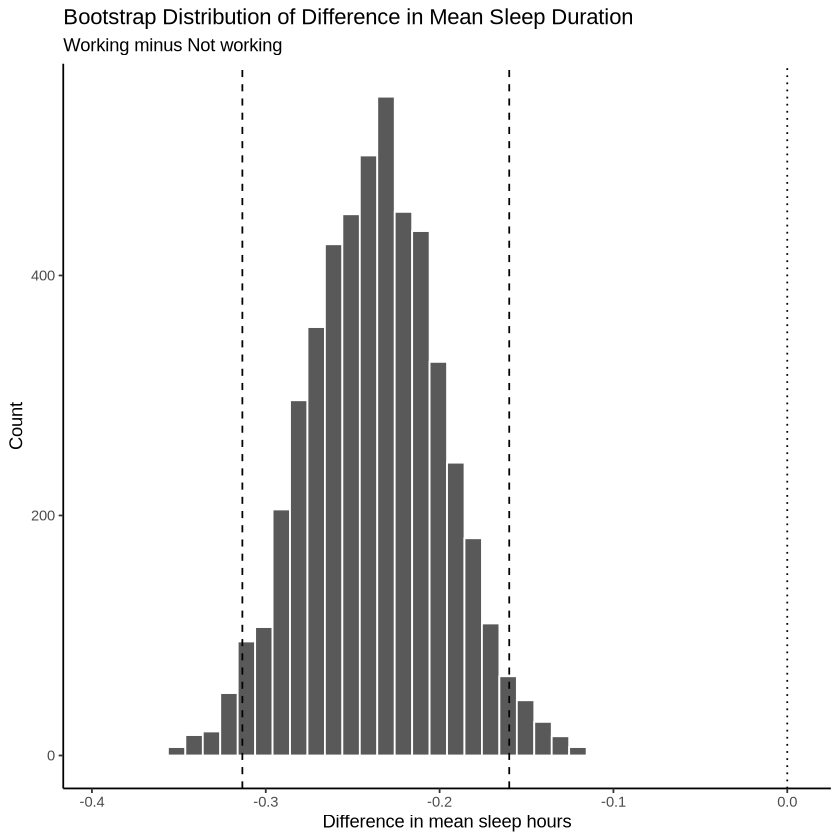

In [7]:
# Visualize bootstrap distribution
ggplot(bootstrap_dist, aes(x = stat)) +
  geom_histogram(
    bins = 40,
    color = "white"
  ) +
  geom_vline(
    xintercept = bootstrap_ci$lower_ci,
    linetype = "dashed"
  ) +
  geom_vline(
    xintercept = bootstrap_ci$upper_ci,
    linetype = "dashed"
  ) +
  geom_vline(
    xintercept = 0,
    linetype = "dotted"
  ) +
  labs(
    title = "Bootstrap Distribution of Difference in Mean Sleep Duration",
    subtitle = "Working minus Not working",
    x = "Difference in mean sleep hours",
    y = "Count"
  ) +
  theme_classic()

In [8]:
# Calculate difference and CI in minutes
obs_diff_minutes <- obs_diff_value * 60

ci_minutes <- bootstrap_ci |>
  mutate(
    lower_minutes = lower_ci * 60,
    upper_minutes = upper_ci * 60
  )

obs_diff_minutes
ci_minutes

[1] -14.24633

lower_ci,upper_ci,lower_minutes,upper_minutes
<dbl>,<dbl>,<dbl>,<dbl>
-0.3134627,-0.1599385,-18.80776,-9.596307


In [9]:
# Summary output
cat(
  "Observed difference in means (Working - Not working):",
  round(obs_diff_value, 3),
  "hours\n"
)

cat(
  "Bootstrap standard error:",
  round(bootstrap_se, 3),
  "hours\n"
)

cat(
  "95% bootstrap confidence interval:",
  round(bootstrap_ci$lower_ci, 3),
  "to",
  round(bootstrap_ci$upper_ci, 3),
  "hours\n"
)

cat(
  "Observed difference:",
  round(obs_diff_minutes, 1),
  "minutes\n"
)

Observed difference in means (Working - Not working): -0.237 hours
Bootstrap standard error: 0.039 hours
95% bootstrap confidence interval: -0.313 to -0.16 hours
Observed difference: -14.2 minutes
